## Image Segmentation with K-Means

Each pixel is represented by

\[
x_i = [R_i, G_i, B_i, x_i, y_i]
\]

**K-Means**

- **Initialize:** Pick k random points as the centroids.
- **Alternate:**
  - Assign each pixel to the closest centroid.
  - Update each centroid to the average of the assigned pixels.
- **Stop:** Stop when the stopping condition is reached.


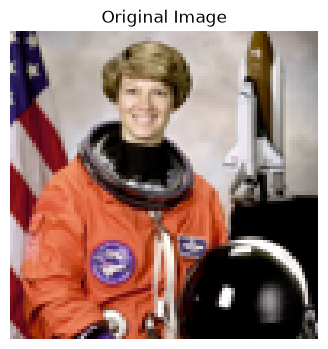

In [1]:
from PIL import Image
from urllib.request import urlretrieve
import matplotlib.pyplot as plt
import random

# Load image
image_url = "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/astronaut.png"
urlretrieve(image_url, "astronaut.png")

image = Image.open("astronaut.png").convert("RGB")
image = image.resize((96, 96))

# Each pixel is represented by [R, G, B, x, y]
FEATURE_LEN = 5

# Preprocess image pixels into data points
data = []

width, height = image.size

for y in range(height):
    for x in range(width):
        R, G, B = image.getpixel((x, y))
        data.append([R, G, B, x, y])

# Plot original image
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


In [2]:
def distance(a, b):
    dist = sum((a[i] - b[i]) ** 2 for i in range(FEATURE_LEN)) ** 0.5
    return dist


def kmeans(data, k, seed=0):
    random.seed(seed)

    # [Initialize]: pick k random points as the centroids
    centroids = random.sample(data, k)

    while True:

        # Alternate

        clusters = [[] for _ in range(k)]

        # Store the assigned cluster index for each data point
        labels = []

        # [Assign] assign each data point to the closest centroid
        for point in data:

            closest_cluster = 0
            closest_distance = distance(point, centroids[0])

            for cluster in range(1, k):
                current_distance = distance(point, centroids[cluster])

                if current_distance < closest_distance:
                    closest_distance = current_distance
                    closest_cluster = cluster

            clusters[closest_cluster].append(point)
            labels.append(closest_cluster)

        # (3) [Update] compute the mean of the assigned points
        new_centroids = []

        for cluster in clusters:
            centroid = []  # centroid = mean of [R, G, B, x, y]

            # Compute the average value for each feature ([0]->R | [1]->G | [2]->B | [3]->x | [4]->y)
            for d in range(FEATURE_LEN):
                mean = sum(point[d] for point in cluster) / len(cluster)
                centroid.append(mean)

            new_centroids.append(centroid)

        # (4) Stop: stop when the centroids do not change
        if new_centroids == centroids:
            break

        centroids = new_centroids

    return labels, centroids


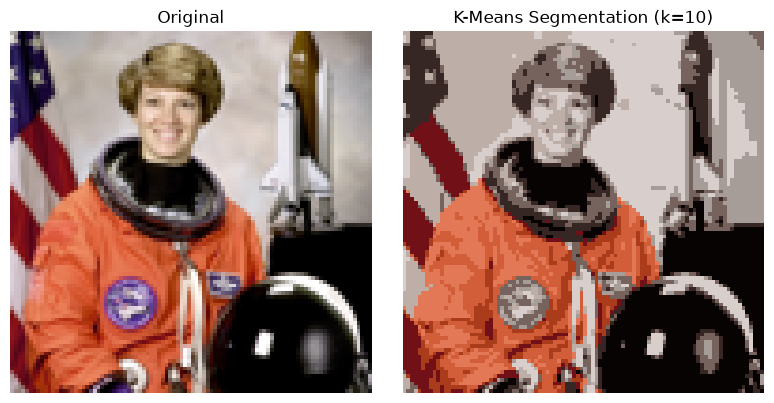

In [11]:
# Hyperparameter
k = 10

labels, centroids = kmeans(data, k=k)

# Create segmented image
segmented_image = Image.new("RGB", image.size)

for i in range(len(data)):
    x = data[i][3]
    y = data[i][4]

    cluster = labels[i]

    R = int(centroids[cluster][0])
    G = int(centroids[cluster][1])
    B = int(centroids[cluster][2])

    segmented_image.putpixel((x, y), (R, G, B))

# Plot original and segmented images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(segmented_image)
axes[1].set_title(f"K-Means Segmentation (k={k})")
axes[1].axis("off")

plt.tight_layout()
plt.show()
